# Cross-validation: does CodeBERT trained on real labelled links help stage 1?

**The question.** Stage 1 ranks code files for each requirement. Does adding a CodeBERT that was fine-tuned on *real, expert-labelled* requirement-to-code links make the ranking better than what the pipeline used before (TF-IDF + MiniLM)?

**The method: leave-one-project-out cross-validation.** There are seven real projects with expert-labelled links: iTrust, eTour, SMOS, eANCI, LibEST, CM-1, EBT. For each project in turn:
1. that project is **held out**: not a single requirement or file of it is used in training;
2. CodeBERT is fine-tuned on the true links of the **other six**;
3. stage 1 is run on the held-out project and compared with the alternatives.

After seven rounds every project has been a test set exactly once, and the results are averaged. This is more trustworthy than one fixed split, because with small datasets one split can be lucky or unlucky.

**Everything shown is computed by this notebook**; nothing is typed in by hand. Training seven models needs a GPU: on a Colab T4 allow about 1 to 1.5 hours for the full run (see `QUICK` in section 2 for a fast check on your Mac).

## 1. Environment

This cell works on your Mac and in Google Colab. On Colab it installs what is missing and asks you to upload `colab_bundle.zip` (the small project files and datasets this notebook needs). On your Mac it just finds the project folder. It also picks the fastest device it can find: a GPU (`cuda` on Colab, `mps` on a Mac) or the CPU.

In [2]:
import os, sys, json, random, time, subprocess
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'sentence-transformers', 'scikit-learn', 'pydantic', 'matplotlib'], check=False)
    if not Path('/content/c4/agents').exists():
        from google.colab import files
        uploaded = files.upload()                       # choose colab_bundle.zip
        import zipfile; zipfile.ZipFile(next(iter(uploaded))).extractall('/content/c4')
    ROOT = Path('/content/c4')
else:
    ROOT = Path.cwd().resolve()
    while not (ROOT / 'agents').is_dir() and ROOT != ROOT.parent:
        ROOT = ROOT.parent                              # find the project folder from wherever the notebook runs
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')

import numpy as np, torch
DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
print('project folder:', ROOT); print('device:', DEVICE, '| on Colab:', IN_COLAB)

project folder: /Users/habbglobal/Desktop/J26-SE-327/project
device: mps | on Colab: False


## Plot style

One small cell that makes every graph below look the same (clean grid, no top/right border) and gives each method its own colour, so a method has the same colour in every graph.

In [3]:
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
COLORS = {'TF-IDF': '#9aa5b1', 'MiniLM': '#4c78a8', 'CodeBERT (not trained)': '#c9a227', 'CodeBERT (fine-tuned)': '#d1495b',
          'TF-IDF + MiniLM': '#2f6f4e', 'TF-IDF + CodeBERT (fine-tuned)': '#9b5de5', 'TF-IDF + MiniLM + CodeBERT': '#e07a1f'}
def color(name):
    return COLORS.get(name, '#444444')

def show_table(rows, columns, width=44):
    """Print {name: {metric: value}} as an aligned text table."""
    print(f"{'':{width}s}" + ''.join(f'{c:>10s}' for c in columns))
    for name, r in rows.items():
        print(f'{name:{width}s}' + ''.join(f'{r[c]:10.3f}' for c in columns))

## 2. Settings

* `FOLDS`: which projects are held out (default: all seven).
* `EPOCHS`, `BATCH`, `LR`, `TAU`: the training settings (explained in the training notebook). A fixed number of epochs is used and **no model selection**, so nothing about the held-out project can influence the model.
* `MAX_TRAIN_ITEMS`: at most this many training pairs per fold (time limit); `0` = use all.
* `REFERENCE_MODEL`: the CodeBERT that is in `models/` today (trained on other data). If it exists it is added as one more column for comparison.
* `QUICK`: a very small run only to check that the notebook works.

In [4]:
BASE = 'microsoft/codebert-base'
PROJECTS = ['itrust', 'etour', 'smos', 'eanci', 'libest', 'cm1', 'ebt']
FOLDS = list(PROJECTS)
EPOCHS, BATCH, LR, TAU, MAX_TRAIN_ITEMS, SEED = 2, 16, 2e-5, 0.05, 2000, 13
CHUNK_WORDS, MAX_LEN = 60, 160                       # stage 1 scores a file by its best 60-word chunk; chunks are read up to 160 tokens
REFERENCE_MODEL = ROOT / 'models' / 'c4-codebert'
QUICK = False                                        # True = tiny run, only to see that everything works
if QUICK:
    FOLDS, EPOCHS, BATCH, MAX_TRAIN_ITEMS = ['cm1', 'ebt'], 1, 8, 64
if not REFERENCE_MODEL.is_dir(): REFERENCE_MODEL = None
print('held-out projects:', FOLDS, '| reference model:', REFERENCE_MODEL)

held-out projects: ['itrust', 'etour', 'smos', 'eanci', 'libest', 'cm1', 'ebt'] | reference model: /Users/habbglobal/Desktop/J26-SE-327/project/models/c4-codebert


## 3. The real projects

Each project has requirements, code files (for CM-1 the targets are design elements) and the **expert-labelled true links** between them. The graph shows how big each one is: some are tiny (CM-1 has 45 links), so single results will be noisy, which is why the confidence intervals later matter.

itrust   131 requirements    392 code files     399 true links
etour     58 requirements    116 code files     308 true links
smos      67 requirements    100 code files    1044 true links
eanci     39 requirements     55 code files     567 true links
libest    52 requirements     14 code files     204 true links
cm1       22 requirements     53 code files      45 true links
ebt       41 requirements     50 code files      98 true links


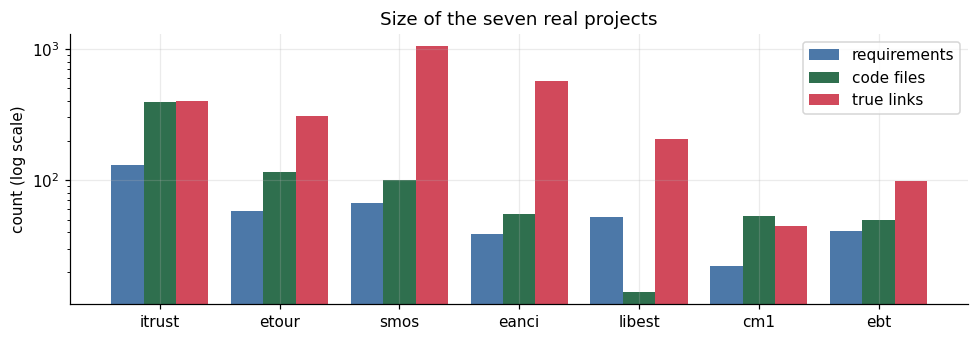

In [5]:
import json
from shared.schemas.traceability import Artifact
PROCESSED = ROOT / 'data' / 'processed'

def load(name):
    """Requirements, code files and the expert-labelled links (as index sets) of one project."""
    arts = [Artifact(**a) for a in json.loads((PROCESSED / name / 'artifacts.json').read_text(encoding='utf-8'))]
    traces = json.loads((PROCESSED / name / 'traces.json').read_text(encoding='utf-8'))
    reqs, code = [a for a in arts if a.type == 'requirement'], [a for a in arts if a.type != 'requirement']
    r_idx, c_idx = {a.id: i for i, a in enumerate(reqs)}, {a.id: i for i, a in enumerate(code)}
    gold = {}
    for t in traces:
        if t['source_id'] in r_idx and t['target_id'] in c_idx: gold.setdefault(r_idx[t['source_id']], set()).add(c_idx[t['target_id']])
    return reqs, code, gold

sizes = {}
for p in PROJECTS:
    r, c, g = load(p); sizes[p] = (len(r), len(c), sum(len(v) for v in g.values()))
    print(f'{p:7s} {len(r):4d} requirements   {len(c):4d} code files   {sizes[p][2]:5d} true links')
x = np.arange(len(PROJECTS)); fig, ax = plt.subplots(figsize=(9, 3.2))
for j, (label, c) in enumerate((('requirements', '#4c78a8'), ('code files', '#2f6f4e'), ('true links', '#d1495b'))):
    ax.bar(x + (j - 1) * 0.27, [sizes[p][j] for p in PROJECTS], 0.27, color=c, label=label)
ax.set_xticks(x); ax.set_xticklabels(PROJECTS); ax.set_yscale('log'); ax.set_ylabel('count (log scale)'); ax.set_title('Size of the seven real projects'); ax.legend(); plt.tight_layout(); plt.show()

## 4. Turning true links into training pairs

Training needs triples of *(requirement, right code, wrong code)*:
* **Right code** = the 60-word chunk of a truly linked file that looks most like the requirement (by TF-IDF). This matches how stage 1 works: it scores a file by its best chunk.
* **Two hard negatives** = the best chunks of the highest-ranked files that are **not** linked to that requirement. These are the tricky cases the model must learn to reject.

`retrieval_text` is the project's own preparation (imports and boilerplate removed, identifiers split into words).

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from agents.traceability_agent.preprocess import retrieval_text
from agents.traceability_agent.retrieval import _chunk_targets, cosine_matrix, embedding_matrix, tfidf_matrix, zscore_fuse

def training_items(name):
    reqs, code, gold = load(name)
    chunks, starts = _chunk_targets(code, retrieval_text, CHUNK_WORDS); ends = list(starts[1:]) + [len(chunks)]
    q_texts = [retrieval_text(r) for r in reqs]
    matrix = TfidfVectorizer(lowercase=True, stop_words='english').fit_transform(q_texts + chunks)
    chunk_scores = cosine_matrix(matrix[:len(reqs)].toarray(), matrix[len(reqs):].toarray())
    best = lambda i, j: chunks[starts[j] + int(np.argmax(chunk_scores[i, starts[j]:ends[j]]))]
    items = []
    for i, truth in gold.items():
        per_file = np.array([chunk_scores[i, starts[j]:ends[j]].max() for j in range(len(code))])
        negatives = [int(j) for j in np.argsort(-per_file) if int(j) not in truth][:2]
        if len(negatives) < 2: continue
        items += [{'query': q_texts[i], 'pos': best(i, j), 'hard': [best(i, n) for n in negatives], 'project': name} for j in truth]
    return items

all_items = {p: training_items(p) for p in PROJECTS}
print({p: len(v) for p, v in all_items.items()}, '-> total', sum(len(v) for v in all_items.values()), 'training pairs available')
ex = all_items['etour'][0]
print('\nREQUIREMENT:', ex['query'][:200], '\n\nRIGHT CHUNK:', ex['pos'][:200], '\n\nHARD NEGATIVE:', ex['hard'][0][:200])

{'itrust': 399, 'etour': 308, 'smos': 1044, 'eanci': 512, 'libest': 204, 'cm1': 45, 'ebt': 98} -> total 2610 training pairs available

REQUIREMENT: Use case name: DeleteCulturalHeritage Description: Delete a cultural object in the system. Participating Actor: initialization Agency Operator Entry Operator conditions: The agency has logged. Flow of 

RIGHT CHUNK: management of cultural heritage unique to agency cultural heritage agency manager cultural heritage common manager cultural heritage agency manager constructor of richicama and initializes the of comm 

HARD NEGATIVE: that the agency operator db agency operator idb agency operator non javadoc see unisa gps etour repository idb operator agency get operator agency bean operator agency get operator agency username sql


## 5. The model, the training loop and the scoring

Same CodeBERT bi-encoder and the same contrastive loss as in the training notebook (each requirement must score its own code above its 2 hard negatives and above the other codes in the batch). Differences here: a **fixed number of epochs, no validation-based choice**, and the loss of every step is kept so it can be plotted.

`BertEmbedder` gives the fine-tuned encoder the same `embed_batch` interface that stage 1 expects, so it plugs into the real `embedding_matrix` function: the test uses the pipeline's own retrieval code, not a copy.

In [7]:
from transformers import AutoModel, AutoTokenizer
from shared.embeddings.embedder import Embedder

class MeanPoolEncoder:
    def __init__(self, name, device):
        self.tok, self.model, self.device = AutoTokenizer.from_pretrained(name), AutoModel.from_pretrained(name).to(device), device
    def encode_tensor(self, texts, max_len):
        batch = self.tok(texts, padding=True, truncation=True, max_length=max_len, return_tensors='pt').to(self.device)
        hidden = self.model(**batch).last_hidden_state; mask = batch['attention_mask'].unsqueeze(-1).to(hidden.dtype)
        return torch.nn.functional.normalize((hidden * mask).sum(1) / mask.sum(1).clamp(min=1), dim=-1)
    def encode(self, texts, max_len, batch=32):
        self.model.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(texts), batch): out.append(self.encode_tensor(texts[i:i + batch], max_len).cpu().numpy())
        return np.concatenate(out)

class BertEmbedder:
    def __init__(self, enc): self.enc = enc
    def embed_batch(self, texts): return self.enc.encode(texts, MAX_LEN).tolist() if texts else []

def fine_tune(enc, items):
    random.seed(SEED); torch.manual_seed(SEED)
    opt = torch.optim.AdamW(enc.model.parameters(), lr=LR, weight_decay=0.01)
    steps = max(1, EPOCHS * (len(items) // BATCH))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / max(1, steps // 10)) * max(0.0, 1 - s / steps))
    losses = []
    for epoch in range(1, EPOCHS + 1):
        enc.model.train(); order = random.sample(items, len(items)); started = time.time()
        for b in range(0, len(order) - BATCH + 1, BATCH):
            chunk = order[b:b + BATCH]
            q = enc.encode_tensor([i['query'] for i in chunk], 64); pos = enc.encode_tensor([i['pos'] for i in chunk], MAX_LEN)
            hard = enc.encode_tensor([h for i in chunk for h in i['hard']], MAX_LEN)
            loss = torch.nn.functional.cross_entropy(q @ torch.cat([pos, hard]).T / TAU, torch.arange(len(chunk), device=q.device))
            loss.backward(); torch.nn.utils.clip_grad_norm_(enc.model.parameters(), 1.0); opt.step(); sched.step(); opt.zero_grad(); losses.append(float(loss))
        print(f'    epoch {epoch}: mean loss {np.mean(losses[-max(1, len(order) // BATCH):]):.3f} ({time.time() - started:.0f} s)')
    return losses

/Users/habbglobal/Desktop/J26-SE-327/project/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/habbglobal/Desktop/J26-SE-327/project/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Metrics

* **recall@k**: of *all* true links of the project, how many are among the k best-ranked files of their requirement (pooled over the project).
* **hit@k**: the share of requirements that have at least one true link in their top k.
* **MRR**: the mean of 1 / (rank of the first true link).
* **Bootstrap**: to know whether a difference is real, the requirements are resampled 2000 times and the number of extra true links found in the top k is recomputed each time. If the 95% interval stays above 0, the improvement is supported; if it contains 0, it could be luck.

In [8]:
KS = (1, 3, 5, 10, 20)
def ranks_of_truth(matrix, gold):
    out = {}
    for i, truth in gold.items():
        position = {int(c): r + 1 for r, c in enumerate(np.argsort(-matrix[i], kind='stable'))}; out[i] = sorted(position[t] for t in truth)
    return out
def summarize(ranks):
    total = sum(len(r) for r in ranks.values())
    out = {f'recall@{k}': sum(sum(x <= k for x in r) for r in ranks.values()) / total for k in KS}
    out.update({f'hit@{k}': float(np.mean([r[0] <= k for r in ranks.values()])) for k in (1, 3, 5, 10)}); out['MRR'] = float(np.mean([1 / r[0] for r in ranks.values()])); return out
def bootstrap(a, b, k, n=2000):
    ids = sorted(a); diff = np.array([sum(x <= k for x in b[i]) - sum(x <= k for x in a[i]) for i in ids], dtype=float); rng = np.random.default_rng(SEED)
    means = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(n)]
    return float(diff.mean()), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

## 6. One fold

`run_fold(held_out)` does the whole procedure for one held-out project: gather the training pairs of the other six, fine-tune a **fresh** CodeBERT, then score the held-out project with: TF-IDF; MiniLM; this fold's CodeBERT; TF-IDF + MiniLM (**before**); TF-IDF + MiniLM + CodeBERT (**after**, the three-signal pipeline). With a reference model it adds the CodeBERT from `models/` too.

In [9]:
mini = Embedder('all-MiniLM-L6-v2'); reference = Embedder(str(REFERENCE_MODEL)) if REFERENCE_MODEL else None

def run_fold(held_out):
    items = [i for p in PROJECTS if p != held_out for i in all_items[p]]
    random.Random(SEED).shuffle(items); items = items[:MAX_TRAIN_ITEMS] if MAX_TRAIN_ITEMS else items
    print(f'\n=== test on {held_out}; trained on the other {len(PROJECTS) - 1} projects ({len(items)} pairs)')
    t0 = time.time(); enc = MeanPoolEncoder(BASE, DEVICE); losses = fine_tune(enc, items); print(f'    trained in {time.time() - t0:.0f} s')
    reqs, code, gold = load(held_out)
    tf = tfidf_matrix(reqs, code, retrieval_text, CHUNK_WORDS); e_mini = embedding_matrix(reqs, code, mini, retrieval_text, CHUNK_WORDS)
    e_bert = embedding_matrix(reqs, code, BertEmbedder(enc), retrieval_text, CHUNK_WORDS)
    methods = {'TF-IDF': tf, 'MiniLM': e_mini, 'CodeBERT (this fold)': e_bert, 'TF-IDF + MiniLM (before)': zscore_fuse([tf, e_mini]),
               'TF-IDF + MiniLM + CodeBERT (after)': zscore_fuse([tf, e_mini, e_bert])}
    if reference is not None:
        e_ref = embedding_matrix(reqs, code, reference, retrieval_text, CHUNK_WORDS)
        methods['TF-IDF + MiniLM + reference CodeBERT'] = zscore_fuse([tf, e_mini, e_ref])
    ranks = {m: ranks_of_truth(x, gold) for m, x in methods.items()}; table = {m: summarize(r) for m, r in ranks.items()}
    boot = {f'top-{k}': dict(zip(('mean', 'lo', 'hi'), bootstrap(ranks['TF-IDF + MiniLM (before)'], ranks['TF-IDF + MiniLM + CodeBERT (after)'], k))) for k in (5, 10)}
    del enc
    if DEVICE == 'cuda': torch.cuda.empty_cache()
    return {'table': table, 'bootstrap': boot, 'losses': losses, 'train_pairs': len(items), 'true_links': sum(len(v) for v in gold.values())}

## 7. Run all folds

This is the long cell (one model is trained per fold). The progress lines show the loss of each epoch and the time. If the Colab connection drops, run this cell again: finished folds are skipped.

In [10]:
folds = globals().get('folds', {})
for p in FOLDS:
    if p not in folds: folds[p] = run_fold(p)
print('\nfinished folds:', list(folds))


=== test on itrust; trained on the other 6 projects (2000 pairs)


/var/folders/bz/0k4cpp4s41b3_t3zdw6jp6s00000gn/T/ipykernel_70829/2202477753.py:34: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  loss.backward(); torch.nn.utils.clip_grad_norm_(enc.model.parameters(), 1.0); opt.step(); sched.step(); opt.zero_grad(); losses.append(float(loss))


    epoch 1: mean loss 2.739 (2314 s)


KeyboardInterrupt: 

## 8. Results

### Table per held-out project
recall@5 / recall@10 / recall@20 (true links found), hit@3 (requirements with a link in the top 3) and MRR.

In [ ]:
cols = ['recall@5', 'recall@10', 'recall@20', 'hit@3', 'MRR']
for p, f in folds.items():
    print(f"\n{p}  ({f['true_links']} true links, trained on {f['train_pairs']} pairs)"); show_table(f['table'], cols)

### Average over all held-out projects
Each project counts once, so a big project cannot dominate. This is the headline table.

In [ ]:
methods = list(next(iter(folds.values()))['table'])
mean = {m: {c: float(np.mean([f['table'][m][c] for f in folds.values()])) for c in cols} for m in methods}
print(f'average over {len(folds)} held-out projects'); show_table(mean, cols)

### Graph 1: before and after, project by project

For each held-out project: recall@10 of the pipeline **before** (TF-IDF + MiniLM) and **after** adding the CodeBERT that never saw that project. Bars where *after* is higher are improvements; lower bars are losses. This shows honestly which projects gain and which do not.

In [ ]:
ps = list(folds); x = np.arange(len(ps)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 3.6))
b = [folds[p]['table']['TF-IDF + MiniLM (before)']['recall@10'] for p in ps]; a = [folds[p]['table']['TF-IDF + MiniLM + CodeBERT (after)']['recall@10'] for p in ps]
ax.bar(x - w / 2, b, w, color=color('TF-IDF + MiniLM'), label='before: TF-IDF + MiniLM'); ax.bar(x + w / 2, a, w, color=color('TF-IDF + MiniLM + CodeBERT'), label='after: + CodeBERT (cross-validated)')
for xi, (bv, av) in enumerate(zip(b, a)): ax.text(xi + w / 2, av + .01, f'{av - bv:+.2f}', ha='center', fontsize=8, color='#2f6f4e' if av >= bv else '#b3261e')
ax.set_xticks(x); ax.set_xticklabels(ps); ax.set_ylabel('recall@10'); ax.set_ylim(0, 1.1); ax.set_title('recall@10 on each held-out project (number = change)'); ax.legend(loc='lower left', fontsize=8)
plt.tight_layout(); plt.show()

### Graph 2: how deep do you have to look?

Average recall when you look at the top 1, 3, 5, 10 and 20 files of every requirement. A curve that is higher means the true links are found earlier. The LLM later checks only the top few candidates, so the left part of the curves matters most.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for m in methods:
    ys = [np.mean([f['table'][m][f'recall@{k}'] for f in folds.values()]) for k in KS]
    nm = 'TF-IDF + MiniLM' if 'before' in m else 'TF-IDF + MiniLM + CodeBERT' if 'after' in m else 'CodeBERT (fine-tuned)' if 'this fold' in m else m
    ax.plot(KS, ys, marker='o', color=color(nm), label=m, linestyle='--' if 'reference' in m else '-')
ax.set_xscale('log'); ax.set_xticks(KS); ax.set_xticklabels([str(k) for k in KS]); ax.set_xlabel('k (files looked at per requirement)'); ax.set_ylabel('average recall@k'); ax.legend(fontsize=7); ax.set_title('Recall by depth, averaged over the held-out projects')
plt.tight_layout(); plt.show()

### Graph 3: is each difference real? (bootstrap)

For each project: how many *extra* true links per requirement the three-signal pipeline finds in the top 10, with its 95% interval. A dot **right of the zero line with the bar not touching it** is a supported improvement; a bar crossing zero means we cannot tell it from luck. Left of zero = worse.

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for i, p in enumerate(ps):
    bt = folds[p]['bootstrap']['top-10']; ok = bt['lo'] > 0
    ax.errorbar(bt['mean'], i, xerr=[[bt['mean'] - bt['lo']], [bt['hi'] - bt['mean']]], fmt='o', color='#2f6f4e' if ok else '#b3261e' if bt['hi'] < 0 else '#6b7280', capsize=3)
ax.axvline(0, color='black', lw=1); ax.set_yticks(range(len(ps))); ax.set_yticklabels(ps); ax.invert_yaxis()
ax.set_xlabel('extra true links per requirement in the top 10 (after minus before), 95% interval'); ax.set_title('green = supported gain, grey = unclear, red = supported loss'); plt.tight_layout(); plt.show()

### Graph 4: the training loss of every fold

Each line is one fold's model. All should fall; if one stays flat the model did not learn in that fold.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for p, f in folds.items():
    l = np.array(f['losses']); win = max(1, len(l) // 15); ax.plot(np.convolve(l, np.ones(win) / win, mode='valid') if len(l) > win else l, label=p)
ax.set_xlabel('training step'); ax.set_ylabel('loss (smoothed)'); ax.legend(ncol=4, fontsize=7); ax.set_title('Training loss per fold'); plt.tight_layout(); plt.show()

## 9. Verdict (written by the notebook from its own numbers)

In [ ]:
b, a = mean['TF-IDF + MiniLM (before)'], mean['TF-IDF + MiniLM + CodeBERT (after)']
wins = [p for p in ps if folds[p]['table']['TF-IDF + MiniLM + CodeBERT (after)']['recall@10'] > folds[p]['table']['TF-IDF + MiniLM (before)']['recall@10']]
loss = [p for p in ps if folds[p]['table']['TF-IDF + MiniLM + CodeBERT (after)']['recall@10'] < folds[p]['table']['TF-IDF + MiniLM (before)']['recall@10']]
supported = [p for p in ps if folds[p]['bootstrap']['top-10']['lo'] > 0]
print(f"average recall@10: before {b['recall@10']:.3f} -> after {a['recall@10']:.3f}   |   average MRR: {b['MRR']:.3f} -> {a['MRR']:.3f}")
print(f'better in {len(wins)} of {len(ps)} projects {wins}; worse in {len(loss)} {loss}; statistically supported gain in {len(supported)} {supported}')
if len(supported) >= len(ps) // 2 + 1: print('CONCLUSION: adding the cross-validated CodeBERT gives a supported improvement.')
elif a['recall@10'] > b['recall@10'] and wins: print('CONCLUSION: a small average gain, but it is not supported project by project: treat it as a possible, unproven improvement.')
else: print('CONCLUSION: adding CodeBERT does not improve stage 1 on real projects.')

## 10. Save the results

In [ ]:
res = (Path('/content/out') if IN_COLAB else ROOT / 'data' / 'results') / 'cross_validation_codebert.json'; res.parent.mkdir(parents=True, exist_ok=True)
res.write_text(json.dumps({'config': {'scheme': 'leave-one-project-out over ' + ', '.join(PROJECTS), 'base': BASE, 'epochs': EPOCHS, 'batch': BATCH, 'lr': LR, 'tau': TAU,
                                      'max_train_items': MAX_TRAIN_ITEMS, 'seed': SEED, 'chunk_words': CHUNK_WORDS, 'quick': QUICK},
                           'mean_over_folds': mean, 'folds': {p: {k: v for k, v in f.items() if k != 'losses'} for p, f in folds.items()}}, indent=1))
print('saved', res)
if IN_COLAB:
    from google.colab import files; files.download(str(res))

## What to say about this notebook

* The test is **leave-one-project-out cross-validation** on the seven real expert-labelled projects: a project is never used to train the model that is tested on it.
* The pipeline *before* is TF-IDF + MiniLM, the pipeline *after* adds CodeBERT. Gains are reported per project with a bootstrap interval, so luck can be told from a real effect.
* The graphs and the verdict above are produced by the notebook from its own run; nothing is entered by hand.